# 01 · TinyVGG baseline

Binary classifier: **REAL** photo vs **AI-generated (FAKE)** image, trained from scratch on a 20k / 4k subset of [CIFAKE](https://huggingface.co/datasets/dragonintelligence/CIFAKE-image-dataset) (32×32 images).

Pipeline: data in `ImageFolder` format → `DataLoader` → TinyVGG CNN → custom training loop → loss curves → saved weights.

Runtime: Colab, T4 GPU.

In [1]:
import os
import random
from pathlib import Path
from timeit import default_timer as timer

import torch
from torch import nn
from torch.utils.data import DataLoader
import torchvision
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

device: cpu


## Data

In [2]:
DATA_DIR = Path("data/cifake")
TRAIN_DIR, TEST_DIR = DATA_DIR / "train", DATA_DIR / "test"
N_TRAIN, N_TEST = 20_000, 4_000


def download_cifake_subset():
    """Download a balanced CIFAKE subset and save it in ImageFolder format:
    data/cifake/{train,test}/{FAKE,REAL}/*.png"""
    from datasets import load_dataset

    ds = load_dataset("dragonintelligence/CIFAKE-image-dataset")
    names = ds["train"].features["label"].names
    for split, n in [("train", N_TRAIN), ("test", N_TEST)]:
        part = ds[split].shuffle(seed=42).select(range(n))
        for i, ex in enumerate(part):
            cls = "FAKE" if "FAKE" in names[ex["label"]].upper() else "REAL"
            folder = DATA_DIR / split / cls
            folder.mkdir(parents=True, exist_ok=True)
            ex["image"].convert("RGB").save(folder / f"{i}.png")


if TRAIN_DIR.is_dir() and any(TRAIN_DIR.rglob("*.png")):
    print("Data already downloaded.")
else:
    download_cifake_subset()
    print("Done.")

README.md:   0%|          | 0.00/488 [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 42.1MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 8.41MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/100000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/20000 [00:00<?, ? examples/s]

Done.


In [3]:
def walk_through_dir(dir_path):
    for dirpath, dirnames, filenames in os.walk(dir_path):
        print(f"{len(dirnames)} directories and {len(filenames)} images in '{dirpath}'")

walk_through_dir(DATA_DIR)

2 directories and 0 images in 'data/cifake'
2 directories and 0 images in 'data/cifake/train'
0 directories and 10139 images in 'data/cifake/train/REAL'
0 directories and 9861 images in 'data/cifake/train/FAKE'
2 directories and 0 images in 'data/cifake/test'
0 directories and 2029 images in 'data/cifake/test/REAL'
0 directories and 1971 images in 'data/cifake/test/FAKE'


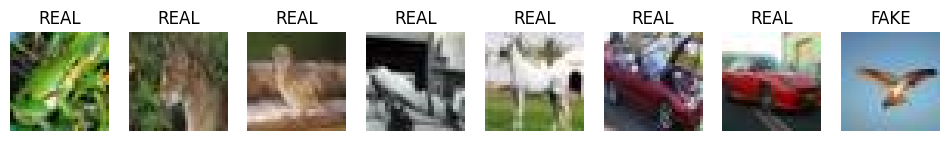

In [4]:
random.seed(42)
paths = list(TRAIN_DIR.glob("*/*.png"))
plt.figure(figsize=(12, 3))
for i, p in enumerate(random.sample(paths, 8)):
    plt.subplot(1, 8, i + 1)
    plt.imshow(plt.imread(p), interpolation="nearest")
    plt.title(p.parent.name)
    plt.axis(False)
plt.show()

## Transforms and DataLoaders

In [5]:
train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),   # augmentation: train only
    transforms.ToTensor(),
])
test_transform = transforms.Compose([
    transforms.ToTensor(),
])

train_data = datasets.ImageFolder(root=TRAIN_DIR, transform=train_transform)
test_data = datasets.ImageFolder(root=TEST_DIR, transform=test_transform)
class_names = train_data.classes
print(class_names, train_data.class_to_idx)

BATCH_SIZE = 64
train_dataloader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True)
test_dataloader = DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False)

X_batch, y_batch = next(iter(train_dataloader))
print(X_batch.shape, y_batch.shape)

['FAKE', 'REAL'] {'FAKE': 0, 'REAL': 1}
torch.Size([64, 3, 32, 32]) torch.Size([64])


## Model

In [6]:
class TinyVGG(nn.Module):
    """Small CNN in the style of VGG: 2 conv blocks + linear classifier.
    Input: [batch, 3, 32, 32] -> output: [batch, output_shape] logits."""

    def __init__(self, input_shape, hidden_units, output_shape):
        super().__init__()
        self.block_1 = nn.Sequential(
            nn.Conv2d(input_shape, hidden_units, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.Conv2d(hidden_units, hidden_units, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),                      # 32 -> 16
        )
        self.block_2 = nn.Sequential(
            nn.Conv2d(hidden_units, hidden_units, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.Conv2d(hidden_units, hidden_units, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),                      # 16 -> 8
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(hidden_units * 8 * 8, output_shape),
        )

    def forward(self, x):
        return self.classifier(self.block_2(self.block_1(x)))

In [7]:
torch.manual_seed(42)
model_0 = TinyVGG(input_shape=3, hidden_units=10, output_shape=len(class_names)).to(device)
print(model_0(X_batch.to(device)).shape)   # sanity check: [64, 2]

torch.Size([64, 2])


## Training loop

In [8]:
def accuracy_fn(y_true, y_pred):
    return torch.eq(y_true, y_pred).sum().item() / len(y_pred) * 100


def train_step(model, dataloader, loss_fn, optimizer, accuracy_fn, device):
    model.train()
    train_loss, train_acc = 0, 0
    for X, y in dataloader:
        X, y = X.to(device), y.to(device)
        logits = model(X)
        loss = loss_fn(logits, y)
        train_loss += loss.item()
        train_acc += accuracy_fn(y, logits.argmax(dim=1))
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    train_loss /= len(dataloader)
    train_acc /= len(dataloader)
    return train_loss, train_acc


def test_step(model, dataloader, loss_fn, accuracy_fn, device):
    model.eval()
    test_loss, test_acc = 0, 0
    with torch.inference_mode():
        for X, y in dataloader:
            X, y = X.to(device), y.to(device)
            logits = model(X)
            test_loss += loss_fn(logits, y).item()
            test_acc += accuracy_fn(y, logits.argmax(dim=1))
    test_loss /= len(dataloader)
    test_acc /= len(dataloader)
    return test_loss, test_acc


def train(model, train_dataloader, test_dataloader, loss_fn, optimizer, epochs, device):
    results = {"train_loss": [], "train_acc": [], "test_loss": [], "test_acc": []}
    for epoch in range(epochs):
        train_loss, train_acc = train_step(model, train_dataloader, loss_fn, optimizer, accuracy_fn, device)
        test_loss, test_acc = test_step(model, test_dataloader, loss_fn, accuracy_fn, device)
        print(f"epoch {epoch}: train loss {train_loss:.4f}, acc {train_acc:.1f}% | "
              f"test loss {test_loss:.4f}, acc {test_acc:.1f}%")
        results["train_loss"].append(train_loss)
        results["train_acc"].append(train_acc)
        results["test_loss"].append(test_loss)
        results["test_acc"].append(test_acc)
    return results

## Train

In [9]:
torch.manual_seed(42)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params=model_0.parameters(), lr=0.001)

start = timer()
model_0_results = train(model_0, train_dataloader, test_dataloader, loss_fn, optimizer, epochs=5, device=device)
print(f"train time: {timer() - start:.1f} s")

epoch 0: train loss 0.5480, acc 70.4% | test loss 0.4227, acc 80.6%
epoch 1: train loss 0.4124, acc 81.6% | test loss 0.3992, acc 82.3%
epoch 2: train loss 0.3838, acc 83.5% | test loss 0.3742, acc 84.4%
epoch 3: train loss 0.3560, acc 85.1% | test loss 0.3503, acc 85.4%
epoch 4: train loss 0.3292, acc 86.4% | test loss 0.3218, acc 87.2%
train time: 140.2 s


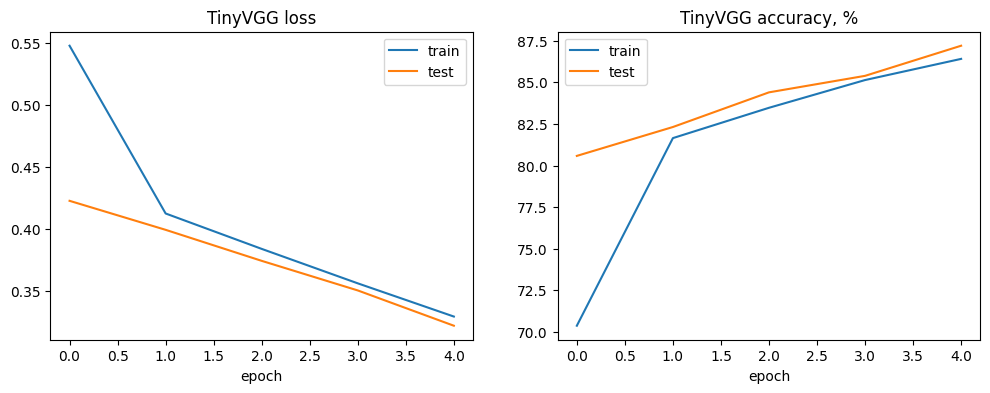

In [10]:
def plot_loss_curves(results, title=""):
    epochs = range(len(results["train_loss"]))
    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    plt.plot(epochs, results["train_loss"], label="train")
    plt.plot(epochs, results["test_loss"], label="test")
    plt.title(f"{title} loss"); plt.xlabel("epoch"); plt.legend()
    plt.subplot(1, 2, 2)
    plt.plot(epochs, results["train_acc"], label="train")
    plt.plot(epochs, results["test_acc"], label="test")
    plt.title(f"{title} accuracy, %"); plt.xlabel("epoch"); plt.legend()
    plt.show()

plot_loss_curves(model_0_results, "TinyVGG")

## Save the model

In [11]:
MODEL_PATH = Path("models") / "tinyvgg_v0.pth"
MODEL_PATH.parent.mkdir(exist_ok=True)
torch.save(model_0.state_dict(), MODEL_PATH)

# check: a fresh model with loaded weights gives the same test accuracy
loaded = TinyVGG(input_shape=3, hidden_units=10, output_shape=len(class_names)).to(device)
loaded.load_state_dict(torch.load(MODEL_PATH, map_location=device))
print(test_step(loaded, test_dataloader, loss_fn, accuracy_fn, device))

(0.3217678216714708, 87.20238095238095)
